# Tdata gathering and processing module development

Jupyter notebook dependencies:

In [1]:
import sys
import os

# Get the absolute path of the parent directory
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))

# Add the parent directory to sys.path
if parent_dir not in sys.path:
    sys.path.append(parent_dir)

TOKEN = 't.DBEaAVcPDDWGkElTk898UNX9yH_ADegVdZgaWKC4a-Ktgz1sbbd-G_9yQf0PeiVEeKuoMWEpUuMT-TNCQzaw1g'

Module dependencies:

In [2]:
import requests
import pandas as pd
import pandas_ta as ta
import logging
import time
import mplfinance as mpf
import matplotlib.pyplot as plt

from datetime import timedelta
from bs4 import BeautifulSoup
from xgboost import XGBClassifier

from tinkoff.invest.sandbox.client import SandboxClient as Client
from tinkoff.invest import SecurityTradingStatus
from tinkoff.invest.services import InstrumentsService
from tinkoff.invest.utils import quotation_to_decimal

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report


ModuleNotFoundError: No module named 'pandas_ta'

## 1. Data ingestion functionality:

In [ ]:

def extract_tickers(url="https://www.tradingview.com/symbols/RUS-RTSI/components/"):
    retries = 3  # Number of retries
    backoff_factor = 2  # Exponential backoff factor (seconds)

    for attempt in range(retries):
        try:
            # Send a GET request to the webpage
            response = requests.get(url, timeout=10)
            response.raise_for_status()  # Check for request errors

            # Parse the HTML content
            soup = BeautifulSoup(response.text, 'html.parser')

            # Find all rows matching the pattern
            rows = soup.find_all('tr', class_="row-RdUXZpkv listRow")

            # Extract tickers from the 'data-rowkey' attribute
            tickers = [row['data-rowkey'].split(':')[1] for row in rows if 'data-rowkey' in row.attrs]

            return tickers

        except requests.exceptions.RequestException as e:
            print(f"Attempt {attempt + 1} failed: {e}")
            if attempt < retries - 1:  # Retry if there are attempts left
                sleep_time = backoff_factor * (2 ** attempt)
                print(f"Retrying in {sleep_time} seconds...")
                time.sleep(sleep_time)
            else:
                print("All retries failed. Exiting.")
                raise

def get_figis(input_tickers, TOKEN):
    """Gets list of ticker-figi indexes pairs for given list of tickers"""
    result = []
    
    with Client(TOKEN) as client:
        instruments: InstrumentsService = client.instruments
        tickers = []
        for method in ["shares", "bonds", "etfs", "currencies", "futures"]:
            for item in getattr(instruments, method)().instruments:
                tickers.append(
                    {
                        "name": item.name,
                        "ticker": item.ticker,
                        "class_code": item.class_code,
                        "figi": item.figi,
                        "uid": item.uid,
                        "type": method,
                        "min_price_increment": quotation_to_decimal(
                            item.min_price_increment
                        ),
                        "scale": 9 - len(str(item.min_price_increment.nano)) + 1,
                        "lot": item.lot,
                        "trading_status": str(
                            SecurityTradingStatus(item.trading_status).name
                        ),
                        "api_trade_available_flag": item.api_trade_available_flag,
                        "currency": item.currency,
                        "exchange": item.exchange,
                        "buy_available_flag": item.buy_available_flag,
                        "sell_available_flag": item.sell_available_flag,
                        "short_enabled_flag": item.short_enabled_flag,
                        "klong": quotation_to_decimal(item.klong),
                        "kshort": quotation_to_decimal(item.kshort),
                    }
                )

        tickers_df = pd.DataFrame(tickers)

        for ticker in input_tickers :
            ticker_df = tickers_df[tickers_df["ticker"] == ticker]
            
            if ticker_df.empty:
                logger.error("There is no such ticker: %s", ticker)
                return
    
            figi = ticker_df["figi"].iloc[0]
            
            result.append((ticker, figi))
    return result

def fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN):
    """
    Fetch OHLCV data for multiple FIGIs with progress logging.
    """
    # List to store rows of data
    data_rows = []

    # Define the maximum period per request for each interval
    max_periods = {
        "CANDLE_INTERVAL_1_MIN": timedelta(days=1),
        "CANDLE_INTERVAL_5_MIN": timedelta(days=7),
        "CANDLE_INTERVAL_15_MIN": timedelta(days=21),
        "CANDLE_INTERVAL_HOUR": timedelta(days=90),
        "CANDLE_INTERVAL_2_HOUR": timedelta(days=90),
        "CANDLE_INTERVAL_4_HOUR": timedelta(days=90),
        "CANDLE_INTERVAL_DAY": timedelta(days=365),
        "CANDLE_INTERVAL_WEEK": timedelta(days=365 * 5),
    }

    # Get the maximum allowable period for the given interval
    max_duration = max_periods.get(interval, timedelta(days=1))  # Default to 1 day if interval is unknown

    total_figis = len(ticker_figis)  # Total number of FIGIs to process
    total_data_points = 0  # Total data points fetched

    with Client(TOKEN) as client:
        for figi_index, (ticker, figi) in enumerate(ticker_figis, start=1):  # Enumerate to track progress
            print(f"Processing {ticker} ({figi}) [{figi_index}/{total_figis}]...")
            current_start = start_date
            figi_data_points = 0  # Data points fetched for this FIGI

            while current_start < end_date:
                # Calculate the end of the current chunk
                current_end = min(current_start + max_duration, end_date)
                try:
                    # Fetch candles for the current chunk
                    candles = client.market_data.get_candles(
                        figi=figi,
                        from_=current_start,
                        to=current_end,
                        interval=interval,
                    )

                    # Append each candle as a row with ticker and figi
                    for candle in candles.candles:
                        row = {
                            "figi": figi,
                            "date": candle.time,
                            "open": candle.open.units + candle.open.nano / 1e9,
                            "high": candle.high.units + candle.high.nano / 1e9,
                            "low": candle.low.units + candle.low.nano / 1e9,
                            "close": candle.close.units + candle.close.nano / 1e9,
                            "volume": candle.volume,
                            "tic": ticker,
                            "day": candle.time.weekday(),
                        }
                        data_rows.append(row)
                        figi_data_points += 1

                    # Move to the next time chunk only if the current batch is successful
                    current_start = current_end

                except Exception as e:
                    print(f"Failed to fetch data for FIGI {figi} (Ticker: {ticker}): {e}")

                    # Check if the error is RESOURCE_EXHAUSTED
                    if "RESOURCE_EXHAUSTED" in str(e):
                        # Extract reset time from the metadata if available
                        metadata = getattr(e.args[-1], 'ratelimit_reset', None)
                        reset_time = int(metadata) if metadata else 60  # Default to 60 seconds if not available
                        print(f"Rate limit exceeded. Fetched {figi_data_points} rows so far for {ticker}.")
                        print(f"Sleeping for {reset_time} seconds...")
                        time.sleep(reset_time)
                    else:
                        # Log and continue for other errors
                        # Skip this batch as it's not recoverable
                        break

            # Log progress for the current FIGI
            print(f"Completed {ticker} ({figi}). Total rows fetched for this FIGI: {figi_data_points}.")
            total_data_points += figi_data_points

    # Convert the list of rows into a DataFrame
    df = pd.DataFrame(data_rows)

    # Final log output
    print(f"All rows fetched: {total_data_points} rows in total.")
    return df

def get_rts_data(start_date, end_date, interval, TOKEN):
    tickers = extract_tickers()
    ticker_figis = get_figis(tickers, TOKEN)
    result = fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN)
    return result

## 2. Data processing functionality:
### 2.1. Calculating indicators

In [89]:

def calculate_indicators(df):
    """
    Calculate technical indicators for a given DataFrame.
    Expects the DataFrame to have 'High', 'Low', 'Close', 'Volume', and 'date' columns.
    """
    # Sort by 'date' to ensure chronological order
    df = df.sort_values('date')
    
    # Set 'date' as DatetimeIndex
    df = df.set_index('date')
    
    # Calculate technical indicators
    df['rsi'] = ta.rsi(df['Close'], length=14)
    
    macd = ta.macd(df['Close'], fast=12, slow=26, signal=9)
    df['macd_line'] = macd['MACD_12_26_9']
    df['macd_signal'] = macd['MACDs_12_26_9']
    df['macd_histogram'] = macd['MACDh_12_26_9']
    
    df['sma_12'] = ta.sma(df['Close'], length=12)
    df['sma_26'] = ta.sma(df['Close'], length=26)
    df['sma_50'] = ta.sma(df['Close'], length=50)
    df['sma_100'] = ta.sma(df['Close'], length=100)
    
    df['atr'] = ta.atr(df['High'], df['Low'], df['Close'], length=14)
    
    bb = ta.bbands(df['Close'], length=20, std=2)
    df['bb_lower'] = bb['BBL_20_2.0']
    df['bb_middle'] = bb['BBM_20_2.0']
    df['bb_upper'] = bb['BBU_20_2.0']
    
    df['vwap'] = ta.vwap(df['High'], df['Low'], df['Close'], df['Volume'])
    
    adx = ta.adx(df['High'], df['Low'], df['Close'], length=14)
    df['adx'] = adx['ADX_14']
    df['adx_positive'] = adx['DMP_14']
    df['adx_negative'] = adx['DMN_14']
    
    stoch = ta.stoch(df['High'], df['Low'], df['Close'], k=14, d=3, smooth_k=3)
    df['stoch_k'] = stoch['STOCHk_14_3_3']
    df['stoch_d'] = stoch['STOCHd_14_3_3']
    
    df['obv'] = ta.obv(df['Close'], df['Volume'])
    
    # Drop rows with any NaN values resulting from indicator calculations
    df = df.dropna().reset_index()
    
    return df

def process_file_with_indicators(input_file):
    """
    Processes the input CSV file to calculate technical indicators per ticker and saves the result.
    
    Parameters:
    - input_file (str): Path to the input CSV file.
    
    The function saves the output to a file named '%input%_with_indicators.csv'.
    """
    # Read the entire dataset with parsed 'date' column
    df = pd.read_csv(input_file, parse_dates=["date"])
    
    # Remove timezone information from 'date' to prevent VWAP warnings
    if df['date'].dt.tz is not None:
        df['date'] = df['date'].dt.tz_convert(None).dt.tz_localize(None)
    
    # Rename columns for consistency
    df.rename(columns={
        'open': 'Open',
        'high': 'High',
        'low': 'Low',
        'close': 'Close',
        'volume': 'Volume'
    }, inplace=True)
    
    # Optimize data types to reduce memory usage
    numeric_cols = ['Open', 'High', 'Low', 'Close', 'Volume']
    df[numeric_cols] = df[numeric_cols].astype('float32')
    
    # Sort the DataFrame by 'tic' and 'date' to ensure proper order within each ticker
    df.sort_values(['tic', 'date'], inplace=True)
    
    # Remove duplicate entries based on 'tic' and 'date'
    df = df.drop_duplicates(subset=['tic', 'date'], keep='first')
    
    # Calculate technical indicators for each ticker group
    df = df.groupby('tic').apply(
        lambda g: calculate_indicators(g).assign(tic=g.name),
        include_groups=False
    )
    
    # Generate output filename by appending '_with_indicators' before the file extension
    base, ext = os.path.splitext(input_file)
    output_file = f"{base}_with_indicators{ext}"
    
    # Save the processed DataFrame with indicators to the output CSV file
    df.to_csv(output_file, index=False)
 
process_file_with_indicators('rts_1m_365d.csv')

In [3]:
df = pd.read_csv('rts_1m_365d_with_indicators.csv')
df

,date,figi,Open,High,Low,Close,Volume,day,rsi,macd_line,...,bb_middle,bb_upper,vwap,adx,adx_positive,adx_negative,stoch_k,stoch_d,obv,tic
0,2024-01-02 11:53:00,BBG004S68614,16.251,16.251,16.225,16.225,36.0,1,43.829976,0.003954,...,16.25455,16.315392,16.263777,9.773482,36.801686,49.363056,42.971934,73.092400,41.0,AFKS
1,2024-01-02 11:55:00,BBG004S68614,16.308,16.309,16.308,16.309,14.0,1,56.372325,0.007163,...,16.25865,16.322491,16.264318,9.511203,43.755413,38.718401,42.971934,54.083045,55.0,AFKS
2,2024-01-02 12:02:00,BBG004S68614,16.226,16.226,16.225,16.225,10.0,1,45.444367,0.002895,...,16.25590,16.320559,16.263987,10.046092,35.509191,50.043402,33.333333,39.759067,45.0,AFKS
3,2024-01-02 12:04:00,BBG004S68614,16.308,16.308,16.308,16.308,4.0,1,54.773698,0.006140,...,16.26000,16.326915,16.264135,9.685872,46.080862,41.683940,66.270058,47.525108,49.0,AFKS
4,2024-01-02 12:06:00,BBG004S68614,16.308,16.310,16.308,16.310,78.0,1,54.973397,0.008771,...,16.26420,16.332580,16.266943,9.384820,46.313454,41.504127,66.270058,55.291149,127.0,AFKS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11809032,2024-12-31 11:55:00,TCS00A107T19,4000.000,4000.000,3998.000,4000.000,8.0,1,49.176107,0.172216,...,4000.40000,4006.471244,4004.166700,36.233495,20.646209,31.217607,33.333333,44.444444,3130259.0,YDEX
11809033,2024-12-31 11:56:00,TCS00A107T19,4000.000,4000.000,4000.000,4000.000,1.0,1,49.176107,0.091924,...,4000.57500,4006.382538,4004.166500,35.101317,20.646209,31.217607,33.918129,39.376218,3130259.0,YDEX
11809034,2024-12-31 11:57:00,TCS00A107T19,4000.000,4005.500,4000.000,4005.500,8.0,1,55.589671,0.466717,...,4000.85000,4007.031424,4004.166300,32.613302,28.342167,28.190034,54.641813,40.631092,3130267.0,YDEX
11809035,2024-12-31 11:58:00,TCS00A107T19,4005.000,4005.000,4005.000,4005.000,3.0,1,54.911272,0.715153,...,4001.10000,4007.523395,4004.166300,30.303002,28.075595,27.924892,71.527778,53.362573,3130264.0,YDEX


### 2.2 Visually assessing ohlcv and indicators data




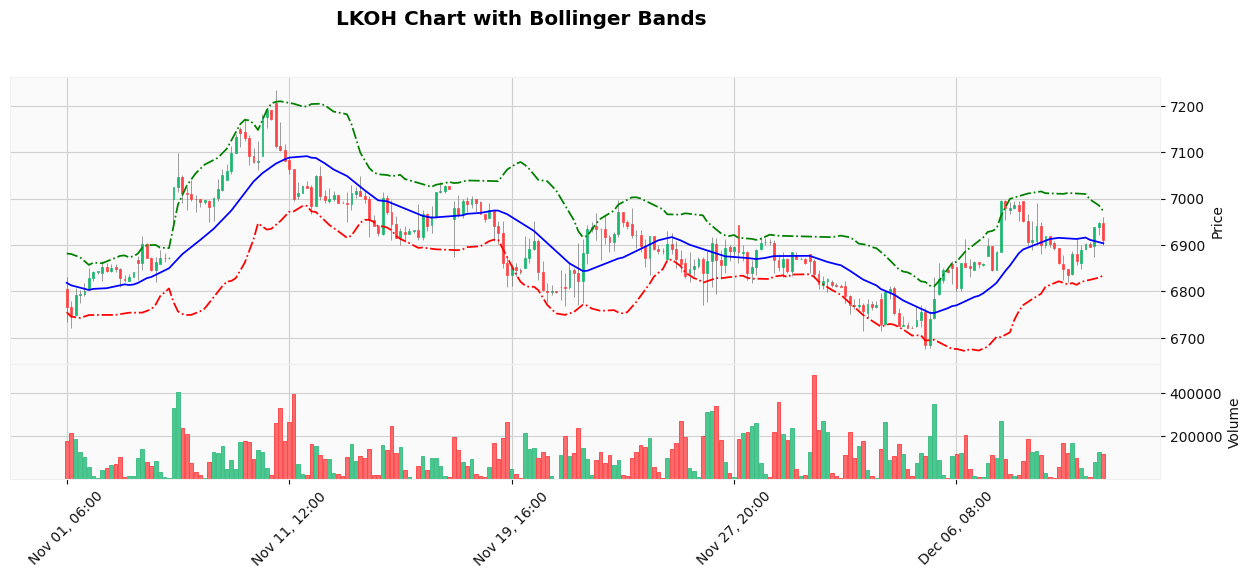

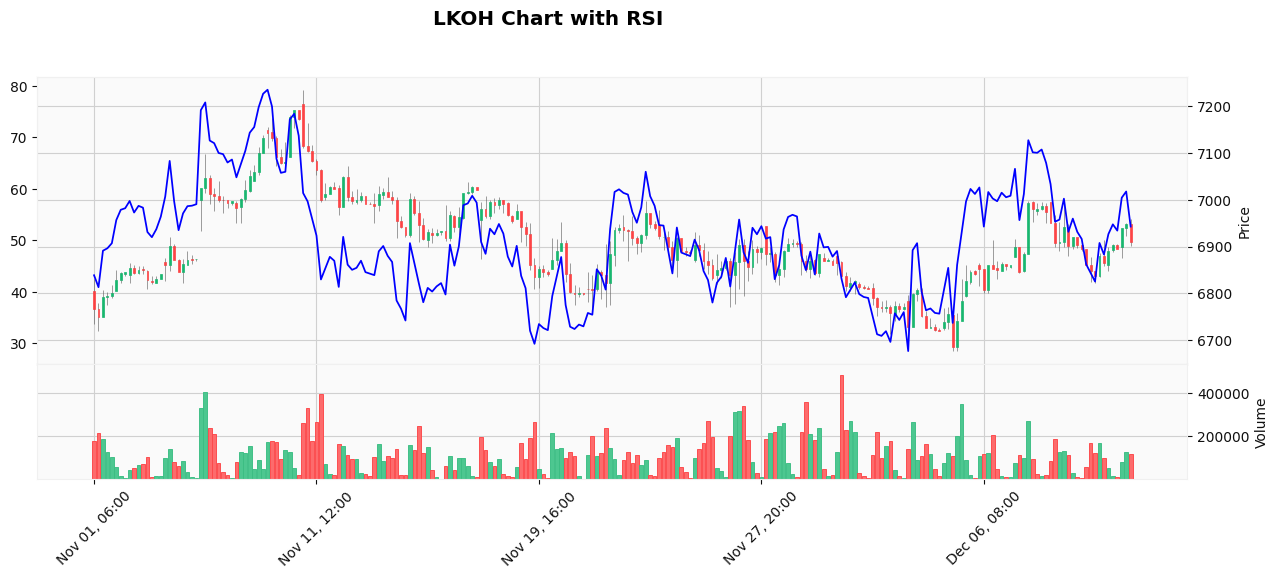

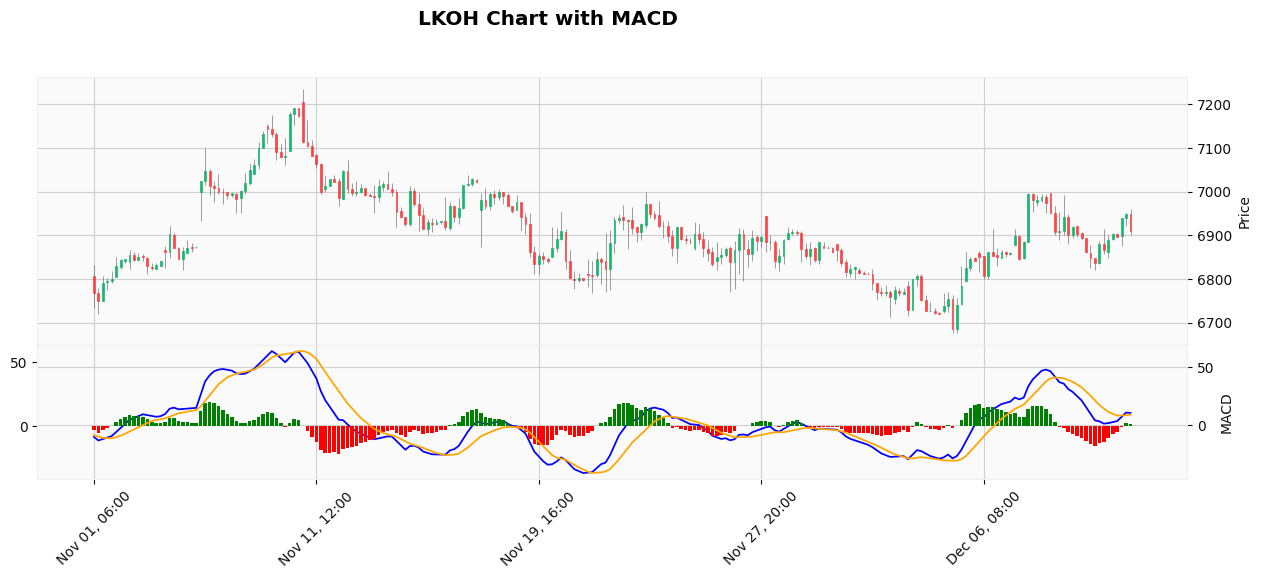

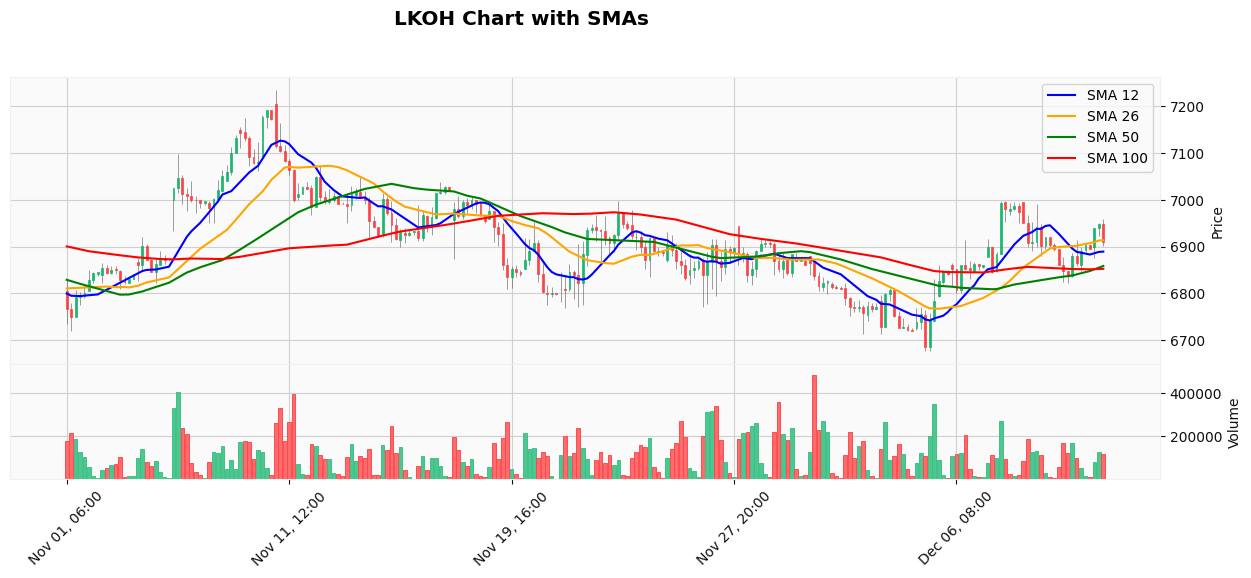

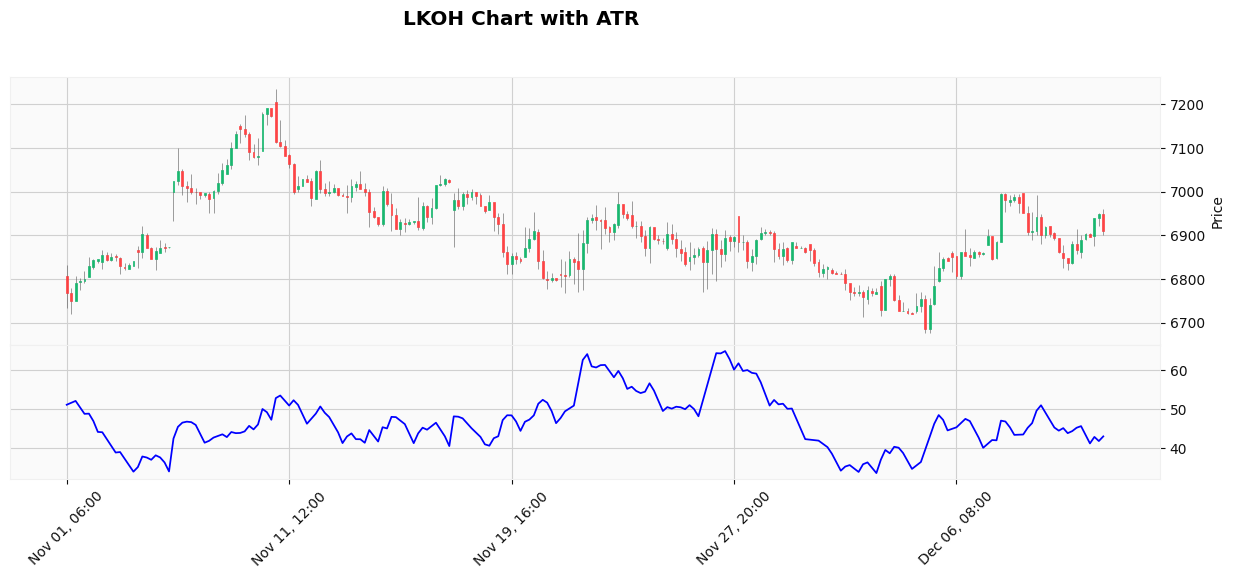

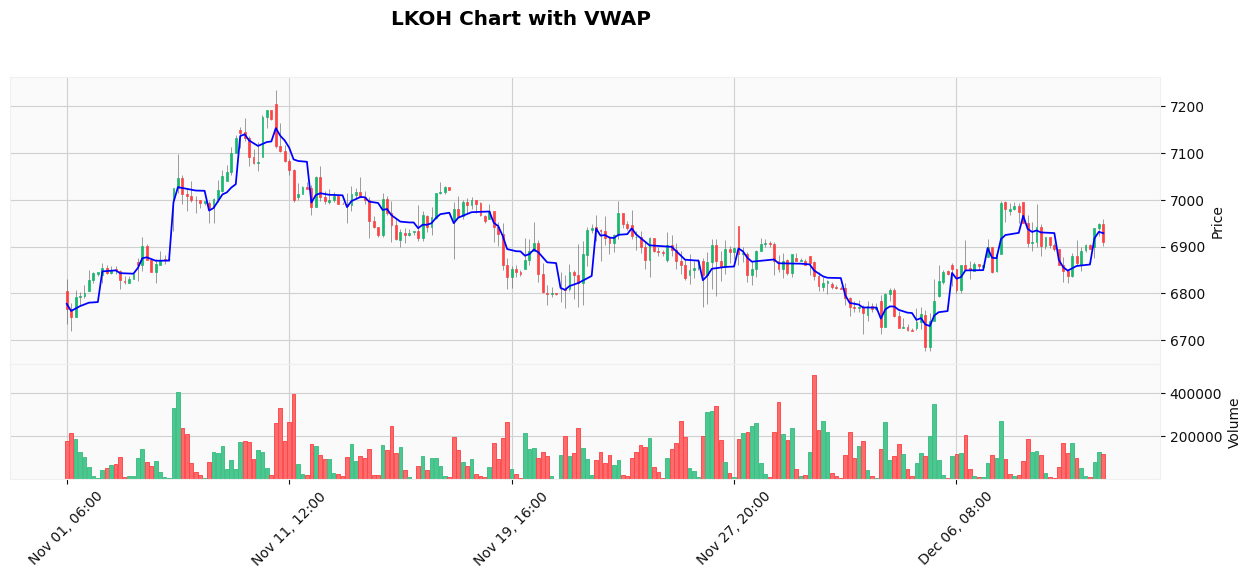

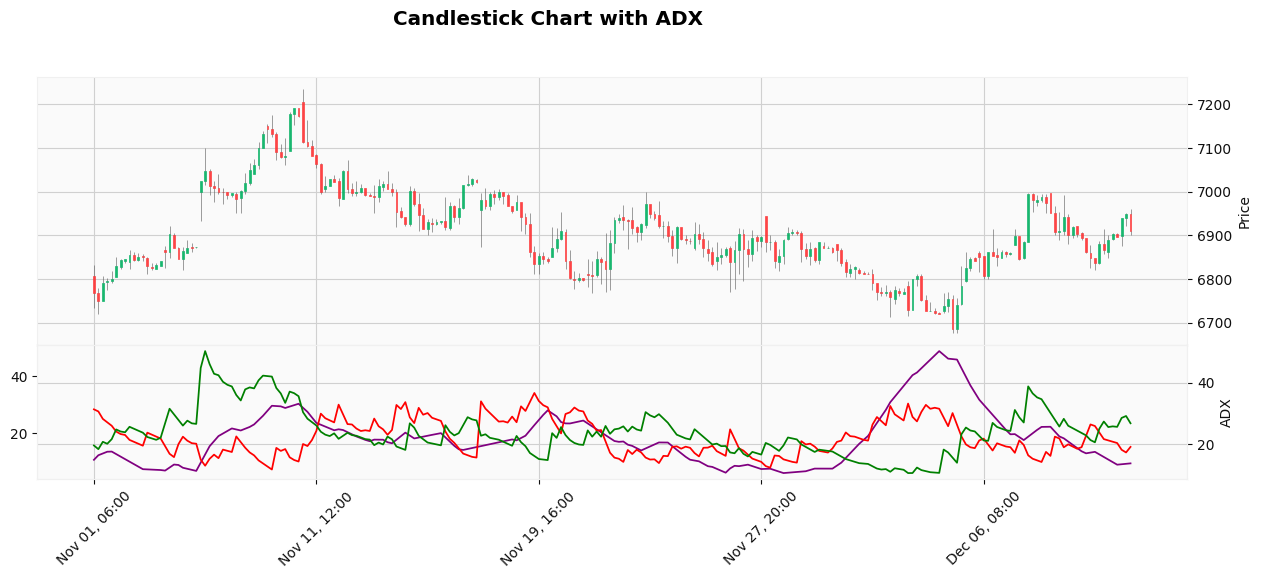

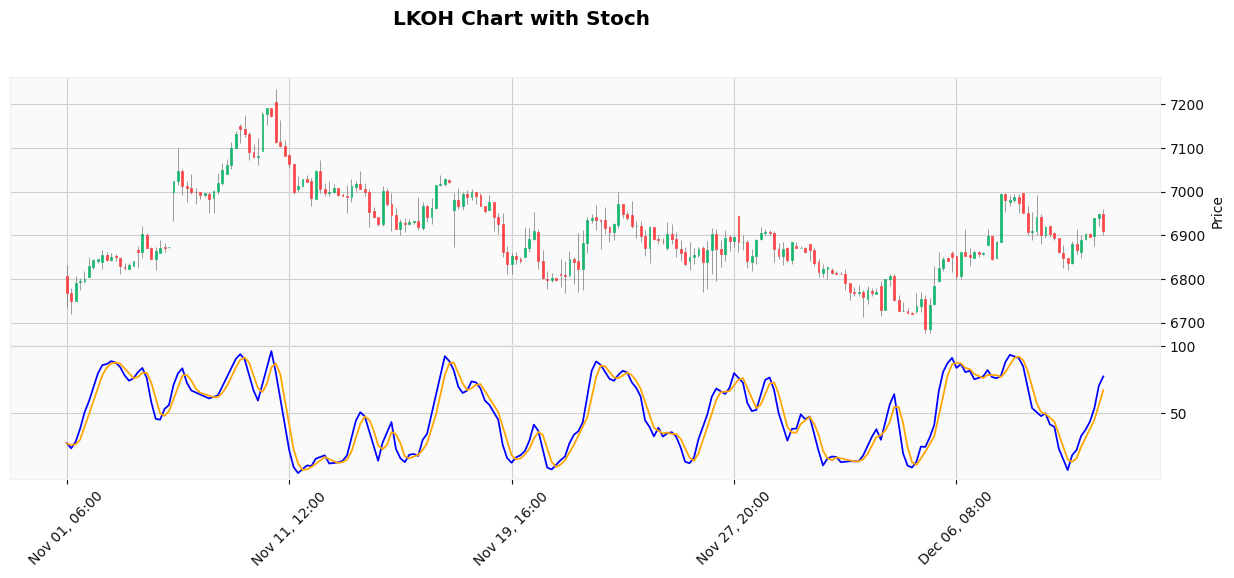

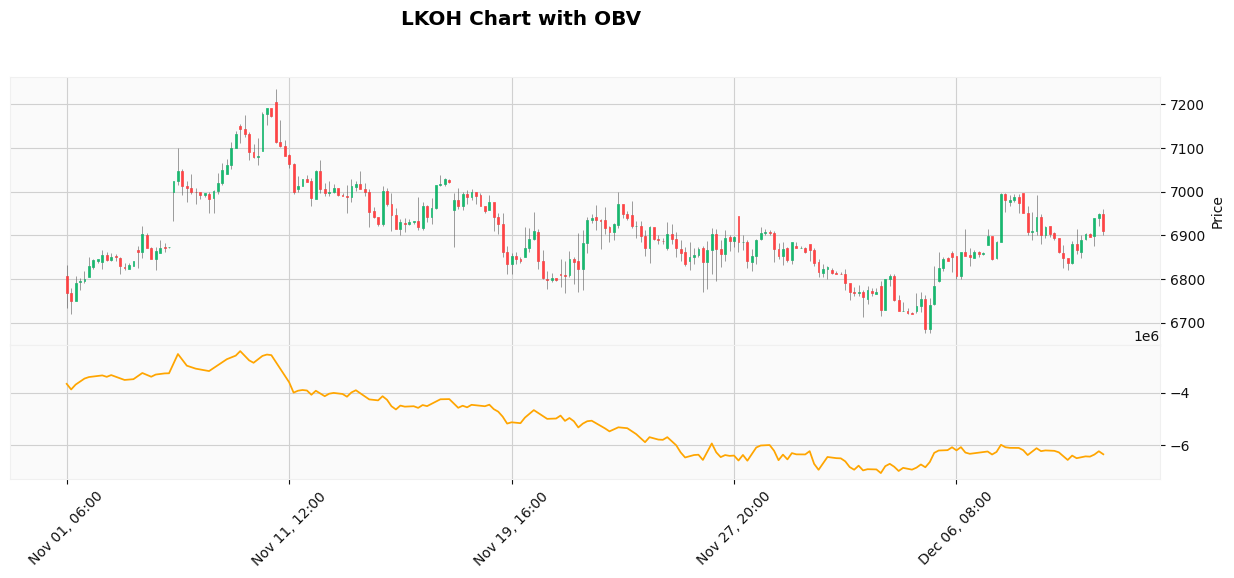

In [60]:

# Set timeframe and ticker
start_date = '2024-11-01'
end_date = '2024-12-31'
ticker = 'LKOH'

# Select data file
df = pd.read_csv('rts_2h_180d_with_indicators.csv')

# Filter for the specified date and ticker
df = df[(df['date'] >= start_date) & (df['date'] <= end_date) & (df['tic'] == ticker)].sort_values('date')

# Reset date format and index
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)

# Add indicators to the candlestick chart
bb_upper_plot = mpf.make_addplot(df['bb_upper'], color='green', linestyle='dashdot')
bb_lower_plot = mpf.make_addplot(df['bb_lower'], color='red', linestyle='dashdot')
bb_middle_plot = mpf.make_addplot(df['bb_middle'], color='blue')

rsi_plot = mpf.make_addplot(df['rsi'], color='blue')

macd_line = mpf.make_addplot(df['macd_line'], panel=1, color='blue', ylabel='MACD')
macd_signal = mpf.make_addplot(df['macd_signal'], panel=1, color='orange')
macd_histogram = mpf.make_addplot(df['macd_histogram'], type='bar', panel=1, color=['green' if v >= 0 else 'red' for v in df['macd_histogram']])

sma_12_plot = mpf.make_addplot(df['sma_12'], color='blue', width=1.5, label='SMA 12')
sma_26_plot = mpf.make_addplot(df['sma_26'], color='orange', width=1.5, label='SMA 26')
sma_50_plot = mpf.make_addplot(df['sma_50'], color='green', width=1.5, label='SMA 50')
sma_100_plot = mpf.make_addplot(df['sma_100'], color='red', width=1.5, label='SMA 100')

atr_plot = mpf.make_addplot(df['atr'], panel=1, color='blue')

vwap_plot = mpf.make_addplot(df['vwap'], color='blue')

adx_plot = mpf.make_addplot(df['adx'], panel=1, color='purple', ylabel='ADX')
adx_positive_plot = mpf.make_addplot(df['adx_positive'], panel=1, color='green')
adx_negative_plot = mpf.make_addplot(df['adx_negative'], panel=1, color='red')

stoch_k_plot = mpf.make_addplot(df['stoch_k'], panel=1, color='blue')
stoch_d_plot = mpf.make_addplot(df['stoch_d'], panel=1, color='orange')

obv_plot = mpf.make_addplot(df['obv'], panel=1, color='orange')

# Plot the candlestick chart with Bollinger Bands
mpf.plot(df, type='candle', volume=True, title=F"{ticker} Chart with Bollinger Bands",
         style='yahoo', figratio=(25, 9), addplot=[bb_upper_plot, bb_lower_plot, bb_middle_plot])

# Plot the candlestick chart with RSI
# To use the RSI indicator, check if the value is above 70 to show an asset is overbought, or below 30 to show it is oversold.
mpf.plot(df, type='candle', volume=True, title=F"{ticker} Chart with RSI",
         style='yahoo', figratio=(25, 9), addplot=[rsi_plot])

# Plot the candlestick chart with MACD indicator
mpf.plot(
    df,
    type='candle',
    style='yahoo',
    figratio=(25, 9),
    addplot=[macd_line, macd_signal, macd_histogram],
    title=F"{ticker} Chart with MACD",
    panel_ratios=(2, 1)  # Main chart is 2x the size of the MACD panel
)

# Plot the candlestick chart with SMAs
mpf.plot(df, type='candle', volume=True, title=F"{ticker} Chart with SMAs",
         style='yahoo', figratio=(25, 9), addplot=[sma_12_plot, sma_26_plot, sma_50_plot, sma_100_plot])

# Plot the candlestick chart with ATR
mpf.plot(
    df,
    type='candle',
    style='yahoo',
    figratio=(25, 9),
    addplot=[atr_plot],
    title=F"{ticker} Chart with ATR",
    panel_ratios=(2, 1)
)

# Plot the candlestick chart with VWAP
mpf.plot(df, type='candle', volume=True, title=F"{ticker} Chart with VWAP",
         style='yahoo', figratio=(25, 9), addplot=[vwap_plot])

# Plot the candlestick chart with ADX
# When the +DMI is above the -DMI, prices are moving up, and ADX measures the strength of the uptrend. 
# When the -DMI is above the +DMI, prices are moving down, and ADX measures the strength of the downtrend.
mpf.plot(
    df,
    type='candle',
    title='Candlestick Chart with ADX',
    style='yahoo',
    figratio=(25, 9),
    addplot=[adx_plot, adx_positive_plot, adx_negative_plot],
    panel_ratios=(2, 1)
)

# Plot the candlestick chart with Stoch osc
# Traditionally, readings over 80 are considered in the overbought range, and readings under 20 are considered oversold
# intersection of these two lines is considered to be a signal that a reversal may be in the works
mpf.plot(
    df,
    type='candle',
    style='yahoo',
    figratio=(25, 9),
    addplot=[stoch_k_plot, stoch_d_plot],
    title=F"{ticker} Chart with Stoch",
    panel_ratios=(2, 1)
)

# Plot the candlestick chart with OBV
mpf.plot(
    df,
    type='candle',
    style='yahoo',
    figratio=(25, 9),
    addplot=[obv_plot],
    title=F"{ticker} Chart with OBV",
    panel_ratios=(2, 1)
)

### 2.3 Feature importance for binary price prediction of single stock (up/down)

In [91]:
# Load processed dataset
df = pd.read_csv('rts_1m_365d_with_indicators.csv', parse_dates=['date'])

# Filter for the specified ticker
df = df[(df['tic'] == 'LKOH')].sort_values('date')

# Define target: 1 if price goes up, 0 otherwise
df['future_return'] = df['Close'].pct_change().shift(-1)  # Future return
df['target'] = (df['future_return'] > 0).astype(int)

# Drop rows with NaN target values
df.dropna(subset=['target'], inplace=True)

# Define feature columns (all indicators)
features = [
    'rsi', 'macd_line', 'macd_signal', 'macd_histogram',
    'sma_12', 'sma_26', 'sma_50', 'sma_100', 'atr',
    'bb_lower', 'bb_middle', 'bb_upper', 'vwap',
    'adx', 'adx_positive', 'adx_negative', 'stoch_k', 'stoch_d', 'obv'
]
X = df[features]
y = df['target']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


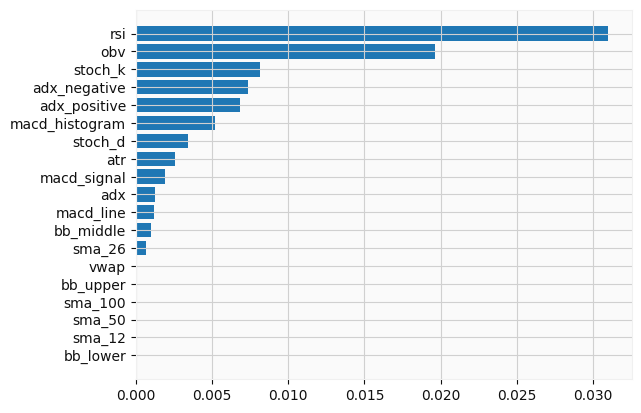

In [92]:
from sklearn.feature_selection import mutual_info_classif

importances = mutual_info_classif(X, y)
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.show()


In [93]:
# Train a Random Forest Classifier
model = RandomForestClassifier(random_state=42, n_estimators=1000, n_jobs=-1)
model.fit(X_train, y_train)

# Predict and evaluate the model
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.64      0.80      0.71     34555
           1       0.50      0.31      0.38     22284

    accuracy                           0.61     56839
   macro avg       0.57      0.55      0.55     56839
weighted avg       0.58      0.61      0.58     56839



           Feature  Importance
0              rsi    0.085723
8              atr    0.067804
15    adx_negative    0.067006
3   macd_histogram    0.065438
17         stoch_d    0.063172
14    adx_positive    0.063035
1        macd_line    0.062654
16         stoch_k    0.061791
13             adx    0.061342
2      macd_signal    0.061082
18             obv    0.054998
12            vwap    0.041418
7          sma_100    0.036627
9         bb_lower    0.035759
11        bb_upper    0.035734
6           sma_50    0.034611
4           sma_12    0.034109
5           sma_26    0.033962
10       bb_middle    0.033735


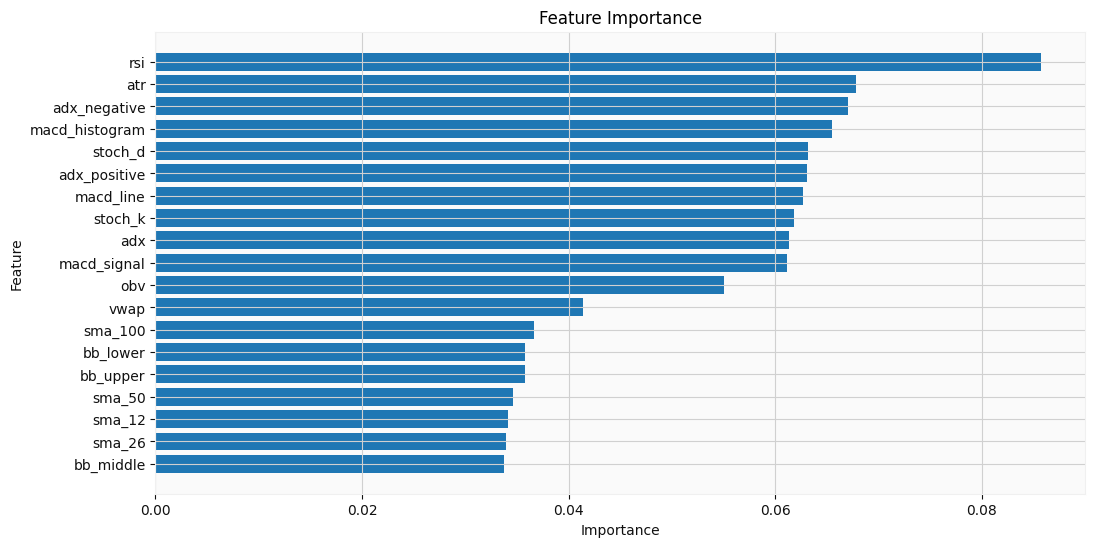

In [94]:
# Extract feature importance
importances = model.feature_importances_

# Rank features by importance
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the ranked features
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(12, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.show()


In [96]:
# Train a Gradient boosting Classifier
model = XGBClassifier(
    random_state=42, 
    n_estimators=1000, 
    learning_rate=0.05,
    n_jobs=-1
)
model.fit(X_train, y_train)

# Predict and evaluate the model
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.64      0.86      0.74     34555
           1       0.55      0.26      0.35     22284

    accuracy                           0.63     56839
   macro avg       0.59      0.56      0.54     56839
weighted avg       0.60      0.63      0.58     56839



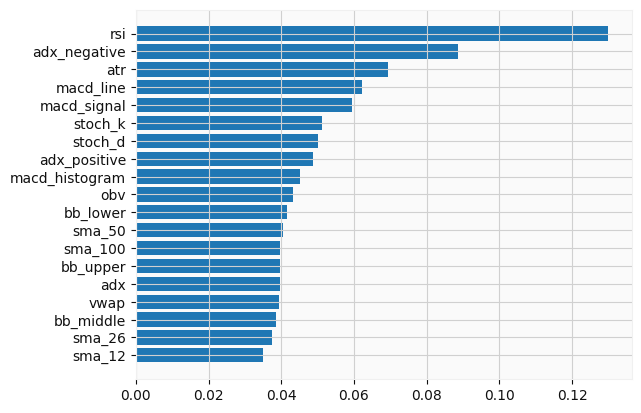

In [97]:
# Feature importance
importances = model.feature_importances_
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.show()


### 2.4 Feature importance for binary price prediction of multiple stocks (up/down)

In [3]:
# Load processed dataset
df = pd.read_csv('rts_1m_365d_with_indicators.csv', parse_dates=['date'])

# Define target: 1 if price goes up, 0 otherwise
df['future_return'] = df['Close'].pct_change().shift(-1)  # Future return
df['target'] = (df['future_return'] > 0).astype(int)

# Drop rows with NaN target values
df.dropna(subset=['target'], inplace=True)

# Define feature columns (all indicators)
features = [
    'rsi', 'macd_line', 'macd_signal', 'macd_histogram',
    'sma_12', 'sma_26', 'sma_50', 'sma_100', 'atr',
    'bb_lower', 'bb_middle', 'bb_upper', 'vwap',
    'adx', 'adx_positive', 'adx_negative', 'stoch_k', 'stoch_d', 'obv'
]
X = df[features]
y = df['target']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [ ]:
from sklearn.feature_selection import mutual_info_classif

importances = mutual_info_classif(X, y)
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.show()


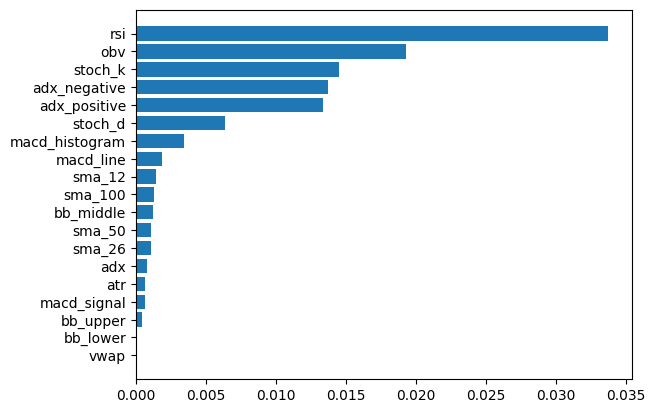

In [6]:
# Plot
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.show()


In [ ]:
# Train a Random Forest Classifier
model = RandomForestClassifier(
    random_state=42, 
    n_estimators=1000, 
    n_jobs=-1
)
model.fit(X_train, y_train)

# Predict and evaluate the model
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))


In [ ]:
# Extract feature importance
importances = model.feature_importances_

# Rank features by importance
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Display the ranked features
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(12, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.show()


In [ ]:
# Train a Gradient boosting Classifier
model = XGBClassifier(
    random_state=42, 
    n_estimators=1000, 
    learning_rate=0.05,
    n_jobs=-1
)
model.fit(X_train, y_train)

# Predict and evaluate the model
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))


In [ ]:
# Feature importance
importances = model.feature_importances_
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.show()
